 iterasi          a          c          b            fa             fc
       0 0.00000000 0.50000000 1.00000000 1.00000000000  3.9872127e-01
       1 0.50000000 0.75000000 1.00000000 0.39872127070 -6.9549998e-01
       2 0.50000000 0.62500000 0.75000000 0.39872127070 -8.4879043e-02
       3 0.50000000 0.56250000 0.62500000 0.39872127070  1.7302341e-01
       4 0.56250000 0.59375000 0.62500000 0.17302340696  4.8070760e-02
       5 0.59375000 0.60937500 0.62500000 0.04807075962 -1.7407965e-02
       6 0.59375000 0.60156250 0.60937500 0.04807075962  1.5580879e-02
       7 0.60156250 0.60546875 0.60937500 0.01558087941 -8.5122656e-04
       8 0.60156250 0.60351562 0.60546875 0.01558087941  7.3804123e-03
       9 0.60351562 0.60449219 0.60546875 0.00738041226  3.2684885e-03
      10 0.60449219 0.60498047 0.60546875 0.00326848846  1.2096047e-03
      11 0.60498047 0.60522461 0.60546875 0.00120960475  1.7943253e-04
      12 0.60522461 0.60534668 0.60546875 0.00017943253 -3.3583616e-04
      

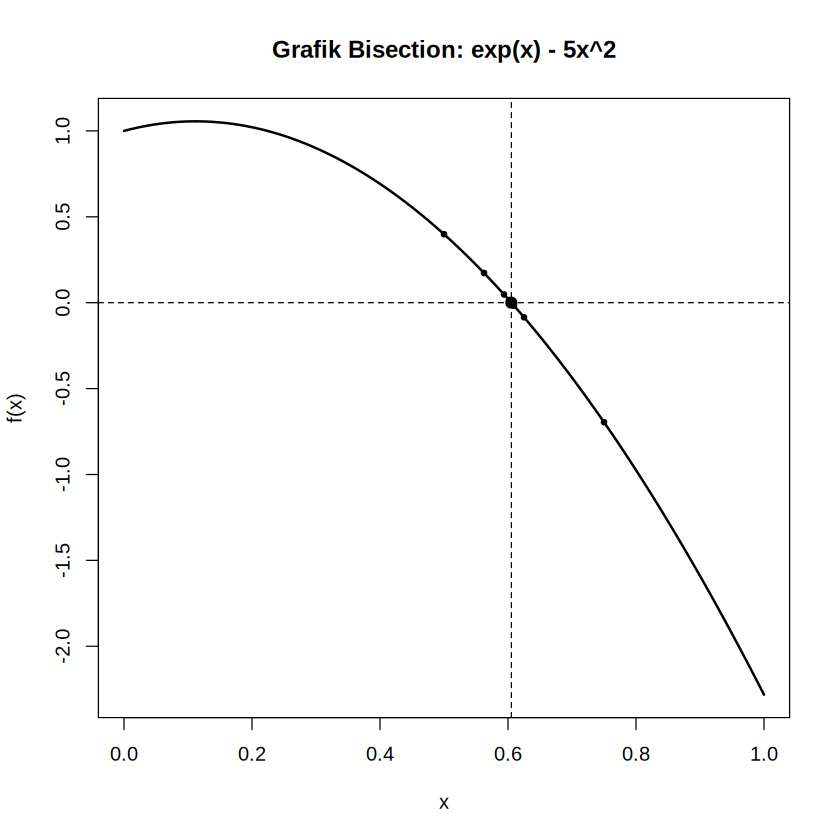

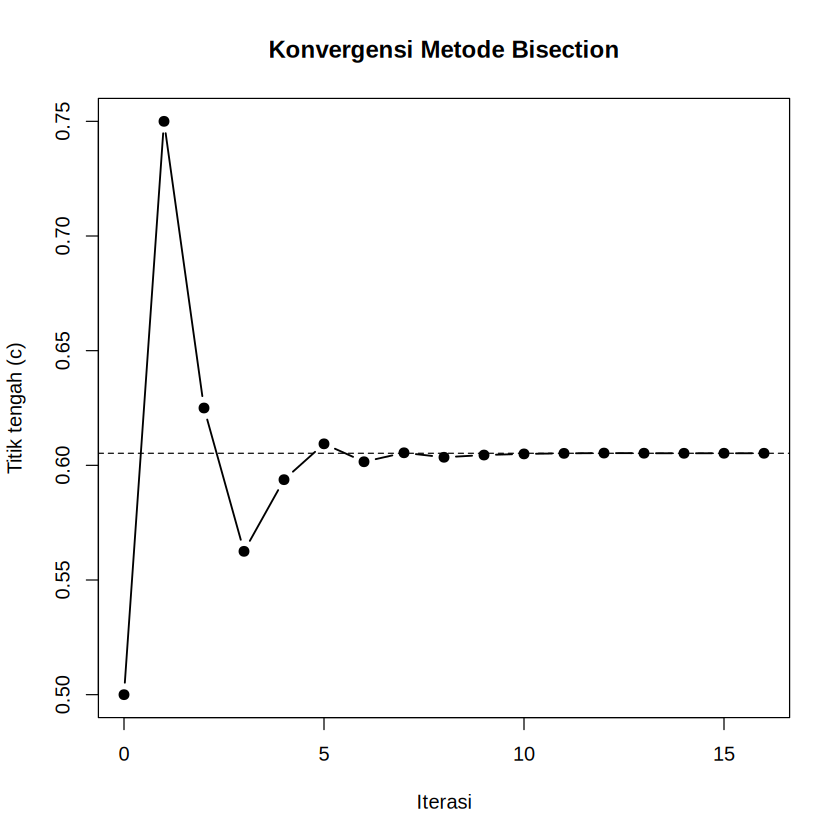

In [5]:

# METODE BISECTION

f <- function(x) {
  exp(x) - 5 * x^2
}

a <- 0
b <- 1
epsilon <- 0.00001
maks_iterasi <- 100

if (f(a) * f(b) > 0) {
  stop("Interval awal tidak memenuhi syarat.")
}

hasil <- data.frame()

for (i in 0:(maks_iterasi - 1)) {

  # Simpan batas sebelum diperbarui
  a_lama <- a
  b_lama <- b

  # Titik tengah(c) dan nilai fungsi
  tengah <- (a + b) / 2
  fa <- f(a)
  fc <- f(tengah)
  fb <- f(b)

  # Pilih interval yang mengandung akar
  if (fc == 0) {
    a <- tengah
    b <- tengah
    selang <- "[c, c]"
  } else if (fa * fc < 0) {
    b <- tengah
    selang <- "[a, c]"
  } else {
    a <- tengah
    selang <- "[c, b]"
  }

  # Lebar interval setelah pembaruan
  lebar <- b - a

  # Catat semua nilai iterasi
  hasil <- rbind(
    hasil,
    data.frame(
      iterasi = i,
      a = a_lama,
      c = tengah,
      b = b_lama,
      fa = fa,
      fc = fc,
      fb = fb,
      selang_baru = selang,
      lebar = lebar
    )
  )

  if (fc == 0 || lebar <= epsilon) {
    break
  }
}

print(hasil, digits = 8, row.names = FALSE)

cat("\nPerkiraan akar =", format(tengah, digits = 10), "\n")
cat("Nilai f(akar)  =", format(f(tengah), digits = 10), "\n")
cat("Jumlah iterasi =", nrow(hasil), "\n")
cat("Lebar interval =", format(lebar, scientific = TRUE), "\n")


# ==========================================
# TAMBAHAN VISUALISASI (PLOT)
# Letakkan setelah kode asli kamu
# ==========================================

# PLOT 1: GRAFIK FUNGSI
x_plot <- seq(0, 1, length.out = 500)

plot(
  x_plot,
  f(x_plot),
  type = "l",
  lwd = 2,
  xlab = "x",
  ylab = "f(x)",
  main = "Grafik Bisection: exp(x) - 5x^2"
)

# Garis horizontal pada f(x) = 0
abline(h = 0, lty = 2)

# Garis vertikal pada titik tengah iterasi terakhir
abline(v = tengah, lty = 2)

# Tampilkan titik tengah dari setiap iterasi
points(
  hasil$c,
  hasil$fc,
  pch = 19,
  cex = 0.6
)

# Tandai titik tengah terakhir
points(
  tengah,
  f(tengah),
  pch = 19,
  cex = 1.2
)


# ==========================================
# PLOT 2: GRAFIK KONVERGENSI
# ==========================================

plot(
  hasil$iterasi,
  hasil$c,
  type = "b",
  pch = 19,
  lwd = 1.5,
  xlab = "Iterasi",
  ylab = "Titik tengah (c)",
  main = "Konvergensi Metode Bisection"
)

# Garis perkiraan akar dari iterasi terakhir
abline(h = tengah, lty = 2)

